In [1]:
#sl_no- 05
#Name- PRASHUK JAIN
#Adm_no- 2026B15310168
#Room_no- RJ107

from google.colab import files
uploaded = files.upload()

Saving Customer Churn.csv to Customer Churn.csv


In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [3]:
import io
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))
print("Dataset load successfull")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset load successfull
Dataset Shape: (3150, 14)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [4]:
print("=" * 50)
print("DATA AUDIT")
print("=" * 50)
print("\nDataset Information:")
df.info()
print("\nRows and Columns:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\nDuplicate Rows:")
print(df.duplicated().sum())
print("\nUnique Values:")
display(df.nunique().to_frame("Unique Values"))
print("\nCategorical Values:")
for col in [
    "Complains",
    "Age Group",
    "Tariff Plan",
    "Status",
    "Churn"
]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))
print("\nChurn Distribution:")
display(df["Churn"].value_counts())
print("\nChurn Percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)
print("\nTarget Balance Audit Complete.")

DATA AUDIT

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int6

,Missing Values
Call Failure,0
Complains,0
Subscription Length,0
Charge Amount,0
Seconds of Use,0
Frequency of use,0
Frequency of SMS,0
Distinct Called Numbers,0
Age Group,0
Tariff Plan,0



Duplicate Rows:
300

Unique Values:


,Unique Values
Call Failure,37
Complains,2
Subscription Length,45
Charge Amount,11
Seconds of Use,1756
Frequency of use,242
Frequency of SMS,405
Distinct Called Numbers,92
Age Group,5
Tariff Plan,2



Categorical Values:

Complains:
Complains
0    2909
1     241
Name: count, dtype: int64

Age Group:
Age Group
3    1425
2    1037
4     395
5     170
1     123
Name: count, dtype: int64

Tariff Plan:
Tariff Plan
1    2905
2     245
Name: count, dtype: int64

Status:
Status
1    2368
2     782
Name: count, dtype: int64

Churn:
Churn
0    2655
1     495
Name: count, dtype: int64

Churn Distribution:


,count
Churn,
0,2655
1,495



Churn Percentage:


,proportion
Churn,
0,84.29
1,15.71



Target Balance Audit Complete.


In [5]:
df = df.copy()
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(
    r"\s+", "_", regex=True)
print("Data Types Before Cleaning:")
display(df.dtypes)
for col in df.columns:
    df[col] = pd.to_numeric(
        df[col], errors="coerce")
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if col == "Churn":
            continue
        df[col] = df[col].fillna(
            df[col].median()
        )
df = df.dropna(subset=["Churn"])
df = df[df["Churn"].isin([0, 1])]
df["Churn"] = df["Churn"].astype(int)
duplicate_count = df.duplicated().sum()
print("\nExact Duplicate Rows:", duplicate_count)
print("Duplicate records are retained because")
print("there is no customer ID to verify their identity.")
print("\nMissing Values After Cleaning:")
display(df.isnull().sum())
print("\nCleaned Dataset Shape:", df.shape)
display(df.head())
print("\nData Cleaning Completed")
for col in ["Complains", "Age_Group", "Tariff_Plan"]:
    df[col] = df[col].astype("category")

Data Types Before Cleaning:


,0
Call_Failure,int64
Complains,int64
Subscription_Length,int64
Charge_Amount,int64
Seconds_of_Use,int64
Frequency_of_use,int64
Frequency_of_SMS,int64
Distinct_Called_Numbers,int64
Age_Group,int64
Tariff_Plan,int64



Exact Duplicate Rows: 300
Duplicate records are retained because
there is no customer ID to verify their identity.

Missing Values After Cleaning:


,0
Call_Failure,0
Complains,0
Subscription_Length,0
Charge_Amount,0
Seconds_of_Use,0
Frequency_of_use,0
Frequency_of_SMS,0
Distinct_Called_Numbers,0
Age_Group,0
Tariff_Plan,0



Cleaned Dataset Shape: (3150, 14)


,Call_Failure,Complains,Subscription_Length,Charge_Amount,Seconds_of_Use,Frequency_of_use,Frequency_of_SMS,Distinct_Called_Numbers,Age_Group,Tariff_Plan,Status,Age,Customer_Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0



Data Cleaning Completed


In [6]:
df["Subscription_Group"] = pd.cut(
    df["Subscription_Length"],
    bins=[0, 12, 24, 36, 48],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-36 Months",
        "37-48 Months"
    ],
    include_lowest=True
)
df["Usage_Group"] = pd.qcut(
    df["Seconds_of_Use"],
    q=4,
    labels=[
        "Low Usage",
        "Medium Usage",
        "High Usage",
        "Very High Usage"
    ],
    duplicates="drop"
)
df["Call_Failure_Group"] = pd.cut(
    df["Call_Failure"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)
df["Total_Communication"] = (
    df["Frequency_of_use"] +
    df["Frequency_of_SMS"]
)
df["Usage_Per_Call_Frequency"] = np.where(
    df["Frequency_of_use"] > 0,
    df["Seconds_of_Use"] / df["Frequency_of_use"],
    0
)
df["Complaint_Flag"] = (
    df["Complains"] == 1
).astype(int)
df["Customer_Value_Per_Month"] = np.where(
    df["Subscription_Length"] > 0,
    df["Customer_Value"] / df["Subscription_Length"],
    0
)
print("New Features Created Successfully!")
new_features = [
    "Subscription_Group",
    "Usage_Group",
    "Call_Failure_Group",
    "Total_Communication",
    "Usage_Per_Call_Frequency",
    "Complaint_Flag",
    "Customer_Value_Per_Month"
]
display(df[new_features].head(10))

New Features Created Successfully!


,Subscription_Group,Usage_Group,Call_Failure_Group,Total_Communication,Usage_Per_Call_Frequency,Complaint_Flag,Customer_Value_Per_Month
0,37-48 Months,High Usage,High,76,61.549296,0,5.201053
1,37-48 Months,Low Usage,Low,12,63.600000,0,1.180385
2,37-48 Months,Medium Usage,High,419,40.883333,0,41.527568
3,37-48 Months,High Usage,High,67,63.606061,0,6.316316
4,37-48 Months,Medium Usage,Medium,60,41.258621,0,3.836974
5,37-48 Months,High Usage,Very High,114,46.036585,0,7.428421
6,37-48 Months,Medium Usage,Medium,324,60.512821,0,32.525263
7,37-48 Months,Very High Usage,Very High,265,75.330579,0,25.552432
8,37-48 Months,Very High Usage,High,169,81.497041,0,14.675789
9,37-48 Months,High Usage,High,85,54.397590,0,5.050526


In [7]:
churned = df[df["Churn"] == 1]
retained = df[df["Churn"] == 0]
print("Total Customers:", len(df))
print("Churned Customers:", len(churned))
print("Retained Customers:", len(retained))
print(
    "Overall Churn Rate:",
    round(df["Churn"].mean() * 100, 2), "%"
)
columns = [
    "Call_Failure",
    "Subscription_Length",
    "Seconds_of_Use",
    "Frequency_of_use",
    "Frequency_of_SMS",
    "Customer_Value"
]
for col in columns:
    values = df[col].to_numpy()
    print("\nStatistics for:", col)
    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Standard Deviation:", round(np.std(values), 2))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))
def bootstrap_ci(data, iterations=2000):
    data = np.asarray(data, dtype=float)
    rng = np.random.default_rng(42)
    samples = rng.choice(
        data,
        size=(iterations, len(data)),
        replace=True
    )
    means = samples.mean(axis=1)
    return np.percentile(means, [2.5, 97.5])
print("\n95% CONFIDENCE INTERVALS")
for col in columns:
    low, high = bootstrap_ci(df[col])
    print(
        col,
        ":",
        round(low, 2),
        "to",
        round(high, 2)
    )
comparison = []
for col in columns:
    comparison.append({
        "Feature": col,
        "Churned Mean": churned[col].mean(),
        "Retained Mean": retained[col].mean(),
        "Difference": (
            churned[col].mean() -
            retained[col].mean()
        )
    })
comparison_df = pd.DataFrame(comparison)
print("\nCUSTOMER GROUP COMPARISON")
display(comparison_df.round(2))

Total Customers: 3150
Churned Customers: 495
Retained Customers: 2655
Overall Churn Rate: 15.71 %

Statistics for: Call_Failure
Mean: 7.63
Median: 6.0
Standard Deviation: 7.26
Minimum: 0
Maximum: 36

Statistics for: Subscription_Length
Mean: 32.54
Median: 35.0
Standard Deviation: 8.57
Minimum: 3
Maximum: 47

Statistics for: Seconds_of_Use
Mean: 4472.46
Median: 2990.0
Standard Deviation: 4197.24
Minimum: 0
Maximum: 17090

Statistics for: Frequency_of_use
Mean: 69.46
Median: 54.0
Standard Deviation: 57.4
Minimum: 0
Maximum: 255

Statistics for: Frequency_of_SMS
Mean: 73.17
Median: 21.0
Standard Deviation: 112.22
Minimum: 0
Maximum: 522

Statistics for: Customer_Value
Mean: 470.97
Median: 228.48
Standard Deviation: 516.93
Minimum: 0.0
Maximum: 2165.28

95% CONFIDENCE INTERVALS
Call_Failure : 7.36 to 7.89
Subscription_Length : 32.23 to 32.83
Seconds_of_Use : 4320.19 to 4626.31
Frequency_of_use : 67.39 to 71.54
Frequency_of_SMS : 69.47 to 77.08
Customer_Value : 453.71 to 488.99

CUSTOMER GR

,Feature,Churned Mean,Retained Mean,Difference
0,Call_Failure,7.48,7.66,-0.18
1,Subscription_Length,31.89,32.66,-0.77
2,Seconds_of_Use,1566.63,5014.22,-3447.59
3,Frequency_of_use,29.13,76.98,-47.85
4,Frequency_of_SMS,15.80,83.87,-68.07
5,Customer_Value,124.81,535.51,-410.70


In [8]:
def bootstrap_difference_ci(
    group1,
    group2,
    iterations=2000
):
    a = np.asarray(group1, dtype=float)
    b = np.asarray(group2, dtype=float)
    rng = np.random.default_rng(42)
    sample_a = rng.choice(
        a,
        size=(iterations, len(a)),
        replace=True
    )
    sample_b = rng.choice(
        b,
        size=(iterations, len(b)),
        replace=True
    )
    differences = (
        sample_a.mean(axis=1) -
        sample_b.mean(axis=1)
    )
    return np.percentile(
        differences,
        [2.5, 97.5]
    )
for col in columns:
    low, high = bootstrap_difference_ci(
        churned[col],
        retained[col]
    )
    print(
        f"{col}: Difference CI = "
        f"{low:.2f} to {high:.2f}"
    )

Call_Failure: Difference CI = -0.90 to 0.58
Subscription_Length: Difference CI = -1.64 to 0.10
Seconds_of_Use: Difference CI = -3660.66 to -3230.08
Frequency_of_use: Difference CI = -51.02 to -44.68
Frequency_of_SMS: Difference CI = -73.04 to -63.12
Customer_Value: Difference CI = -434.75 to -387.20


In [9]:
def churn_analysis(column):
    result = df.groupby(
        column,
        observed=False
    ).agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", "sum"),
        Churn_Rate=("Churn", "mean")
    ).reset_index()
    result["Churn_Rate"] *= 100
    result = result.sort_values(
        "Churn_Rate",
        ascending=False
    )
    print("\nChurn Analysis:", column)
    display(result.round(2))
    return result
tariff_result = churn_analysis("Tariff_Plan")
status_result = churn_analysis("Status")
complaint_result = churn_analysis("Complains")
age_group_result = churn_analysis("Age_Group")
subscription_result = churn_analysis("Subscription_Group")
usage_result = churn_analysis("Usage_Group")
call_failure_result = churn_analysis("Call_Failure_Group")


Churn Analysis: Tariff_Plan


,Tariff_Plan,Total_Customers,Churned_Customers,Churn_Rate
0,1,2905,489,16.83
1,2,245,6,2.45



Churn Analysis: Status


,Status,Total_Customers,Churned_Customers,Churn_Rate
1,2,782,370,47.31
0,1,2368,125,5.28



Churn Analysis: Complains


,Complains,Total_Customers,Churned_Customers,Churn_Rate
1,1,241,200,82.99
0,0,2909,295,10.14


... (4 outputs left out)


Churn Analysis: Usage_Group


,Usage_Group,Total_Customers,Churned_Customers,Churn_Rate
0,Low Usage,788,281,35.66
1,Medium Usage,788,145,18.40
2,High Usage,786,69,8.78
3,Very High Usage,788,0,0.00



Churn Analysis: Call_Failure_Group


,Call_Failure_Group,Total_Customers,Churned_Customers,Churn_Rate
0,Low,960,171,17.81
1,Medium,518,82,15.83
3,Very High,916,137,14.96
2,High,756,105,13.89


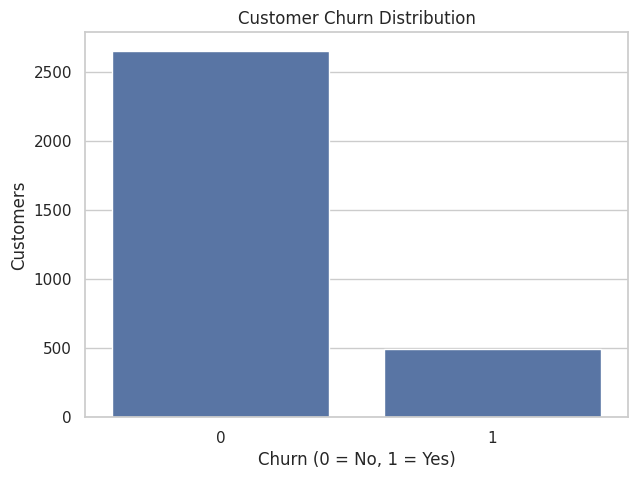

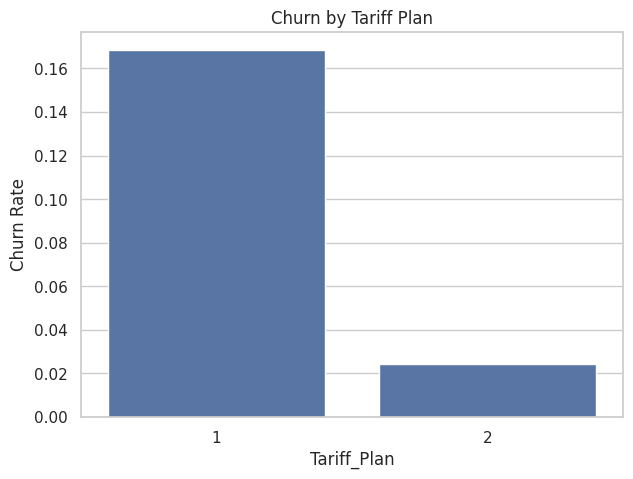

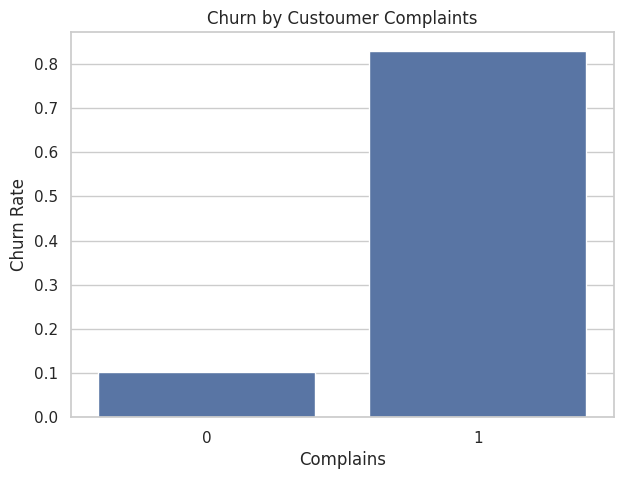

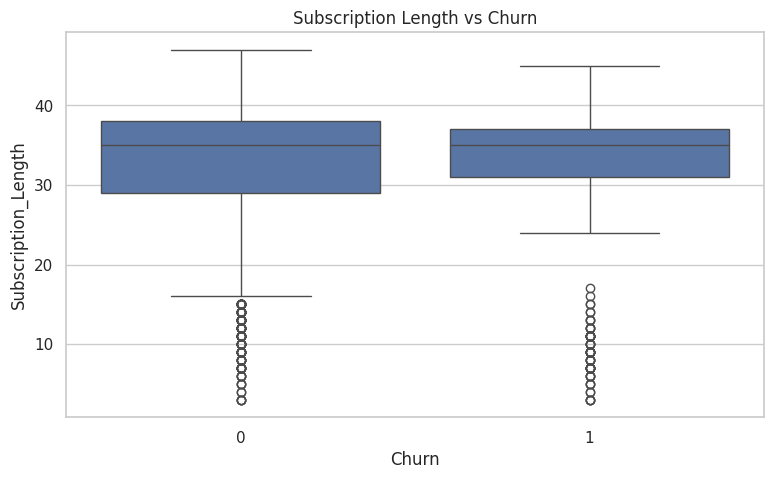

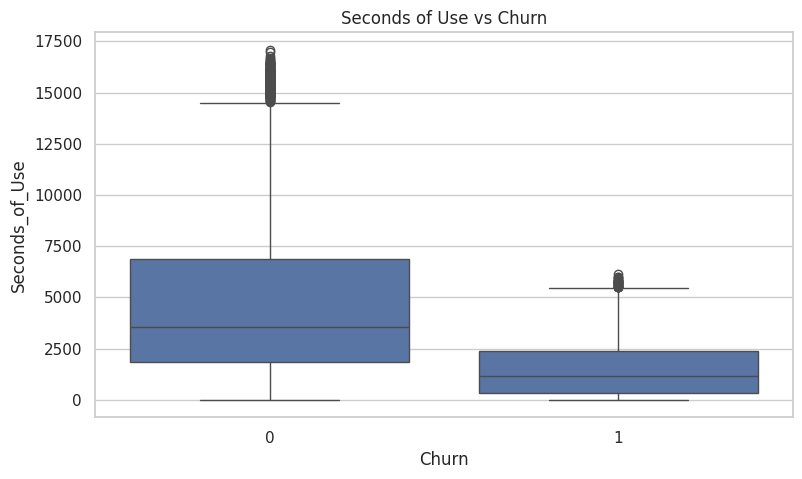

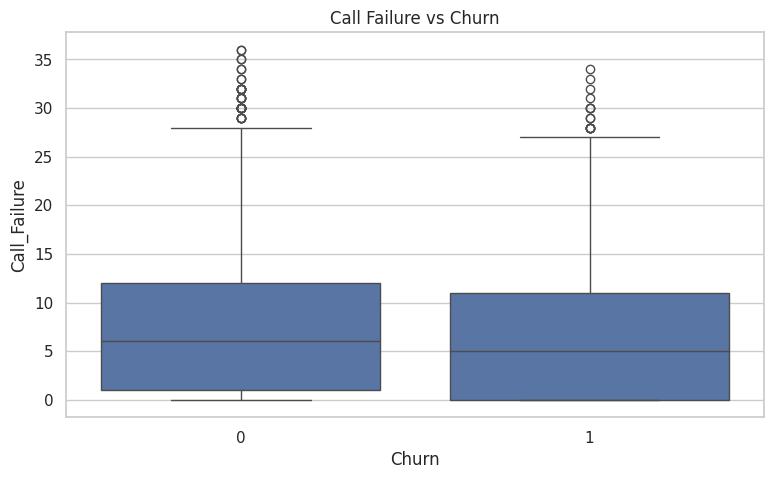

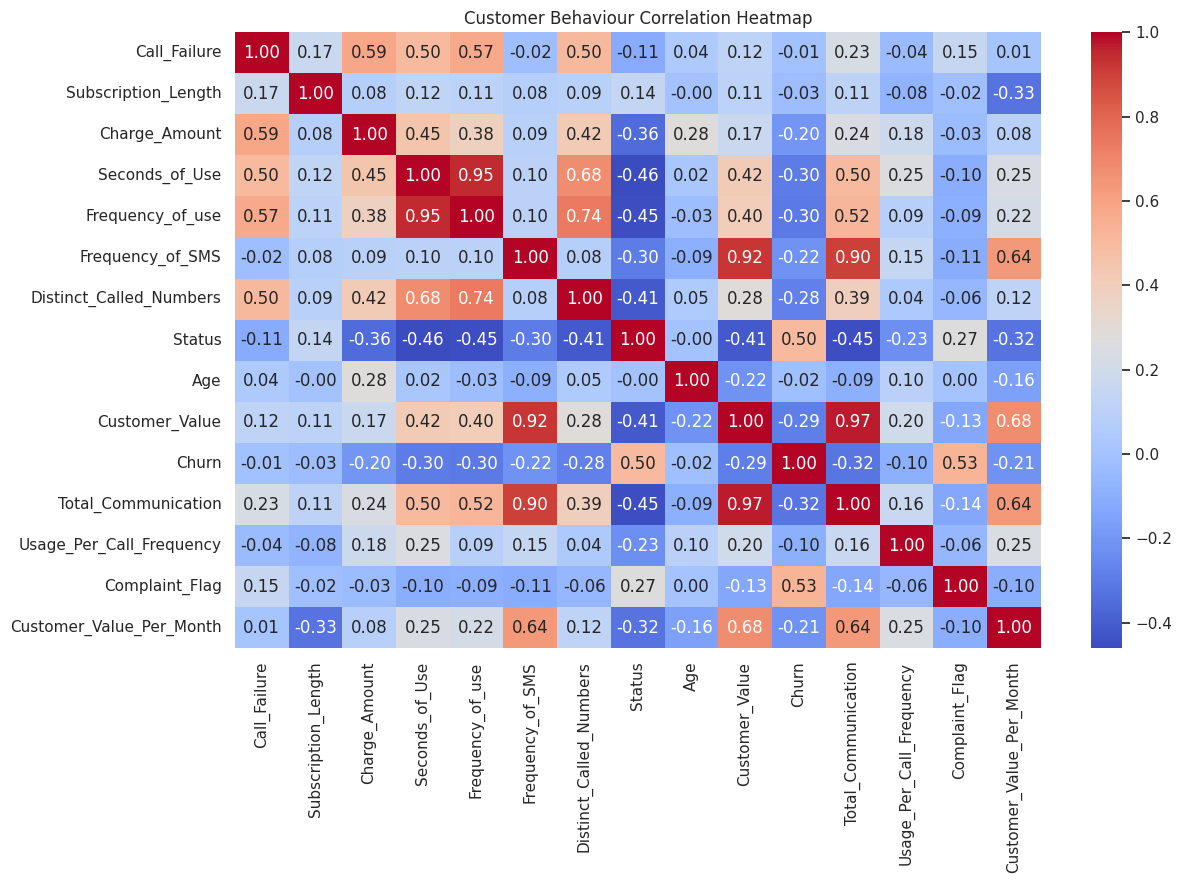

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Customers")
plt.show()
plt.figure(figsize=(7, 5))
sns.barplot(
    data=df,
    x="Tariff_Plan",
    y="Churn",
    errorbar=None
)
plt.title("Churn by Tariff Plan")
plt.ylabel("Churn Rate")
plt.show()
plt.figure(figsize=(7, 5))
sns.barplot(
    data=df,
    x="Complains",
    y="Churn",
    errorbar=None
)
plt.title("Churn by Custoumer Complaints")
plt.ylabel("Churn Rate")
plt.show()
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Churn",
    y="Subscription_Length"
)
plt.title("Subscription Length vs Churn")
plt.show()
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Churn",
    y="Seconds_of_Use"
)
plt.title("Seconds of Use vs Churn")
plt.show()
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Churn",
    y="Call_Failure"
)
plt.title("Call Failure vs Churn")
plt.show()
plt.figure(figsize=(13, 8))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Customer Behaviour Correlation Heatmap")
plt.show()

In [11]:
print("=" * 50)
print("DATA LEAKAGE ANALYSIS")
print("=" * 50)
excluded_columns = [
    "Churn",
    "Status",
    "Customer_Value",
    "Customer_Value_Per_Month"
]
print("\nExcluded from predictive model:")
for col in excluded_columns:
    print("-", col)
print("\nReason:")
print("""
1. Churn is the target variable.
2. Status may reflect the customer's current
   active/inactive state and could reveal churn.
3. Customer Value may contain information calculated
   using data unavailable at prediction time.
4. Customer ID is not available in this dataset.
""")
correlation = df.select_dtypes(
    include=np.number
).corr()["Churn"].sort_values(
    ascending=False
)
print("\nNumerical Feature Correlations with Churn:")
display(correlation.to_frame("Correlation"))
print("""
IMPORTANT:
Correlation does not prove causation.

A feature associated with churn does not necessarily
cause a customer to leave.
""")

DATA LEAKAGE ANALYSIS

Excluded from predictive model:
- Churn
- Status
- Customer_Value
- Customer_Value_Per_Month

Reason:

1. Churn is the target variable.
2. Status may reflect the customer's current
   active/inactive state and could reveal churn.
3. Customer Value may contain information calculated
   using data unavailable at prediction time.
4. Customer ID is not available in this dataset.


Numerical Feature Correlations with Churn:


,Correlation
Churn,1.000000
Complaint_Flag,0.532053
Status,0.498976
Call_Failure,-0.008987
Age,-0.017705
Subscription_Length,-0.032588
Usage_Per_Call_Frequency,-0.097752
Charge_Amount,-0.202305
Customer_Value_Per_Month,-0.213324
Frequency_of_SMS,-0.220754



IMPORTANT:
Correlation does not prove causation.

A feature associated with churn does not necessarily
cause a customer to leave.



In [12]:
X = df.drop(
    columns=excluded_columns)
y = df["Churn"]
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()
print("Numerical Features:")
print(numeric_features)
print("\nCategorical Features:")
print(categorical_features)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print("\nModel train successfully!")

Numerical Features:
['Call_Failure', 'Subscription_Length', 'Charge_Amount', 'Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Age', 'Total_Communication', 'Usage_Per_Call_Frequency', 'Complaint_Flag']

Categorical Features:
['Complains', 'Age_Group', 'Tariff_Plan', 'Subscription_Group', 'Usage_Group', 'Call_Failure_Group']

Training Records: 2520
Testing Records: 630

Model train successfully!


MODEL PERFORMANCE


,Metric,Score
0,Accuracy,0.8254
1,Precision,0.4693
2,Recall,0.8485
3,F1 Score,0.6043
4,ROC-AUC,0.9378



Classification Report:
              precision    recall  f1-score   support

    Retained       0.97      0.82      0.89       531
     Churned       0.47      0.85      0.60        99

    accuracy                           0.83       630
   macro avg       0.72      0.83      0.75       630
weighted avg       0.89      0.83      0.84       630



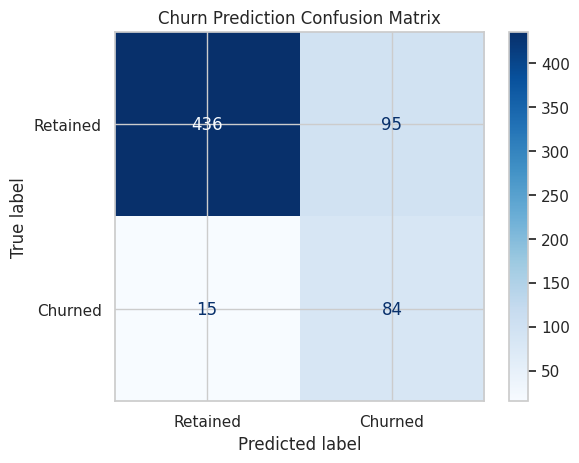

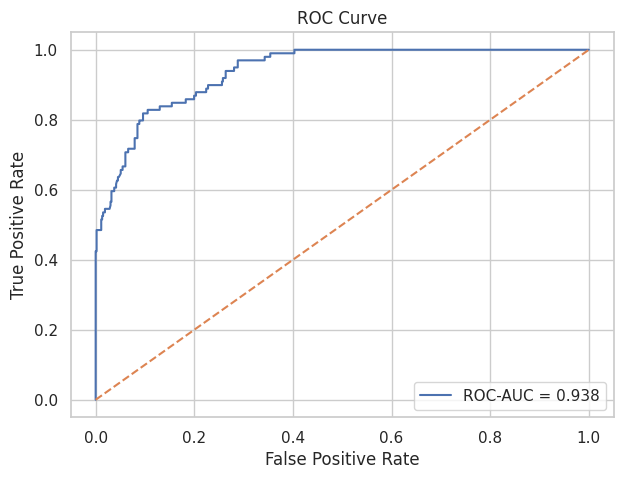

In [13]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)
recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)
f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)
auc = roc_auc_score(y_test, y_prob)
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})
print("MODEL PERFORMANCE")
display(metrics.round(4))
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Retained", "Churned"],
    cmap="Blues"
)
plt.title("Churn Prediction Confusion Matrix")
plt.show()
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)
plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.3f}"
)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

TOP 15 IMPORTANT FEATURES


,Feature,Coefficient,Importance
4,num__Frequency_of_use,-2.2396,2.2396
20,cat__Subscription_Group_0-12 Months,1.9681,1.9681
13,cat__Age_Group_1,-1.7695,1.7695
21,cat__Subscription_Group_13-24 Months,-1.6850,1.6850
8,num__Total_Communication,-1.6086,1.6086
0,num__Call_Failure,1.5443,1.5443
17,cat__Age_Group_5,-1.4806,1.4806
27,cat__Usage_Group_Very High Usage,-1.3062,1.3062
14,cat__Age_Group_2,1.1978,1.1978
16,cat__Age_Group_4,1.1556,1.1556



CUSTOMER RISK SUMMARY


,Risk_Band,Customers,Actual_Churned,Actual_Churn_Rate,Average_Predicted_Risk
0,Low Risk,2027,26,1.28,5.45
1,Medium Risk,373,45,12.06,46.41
2,High Risk,750,424,56.53,81.82


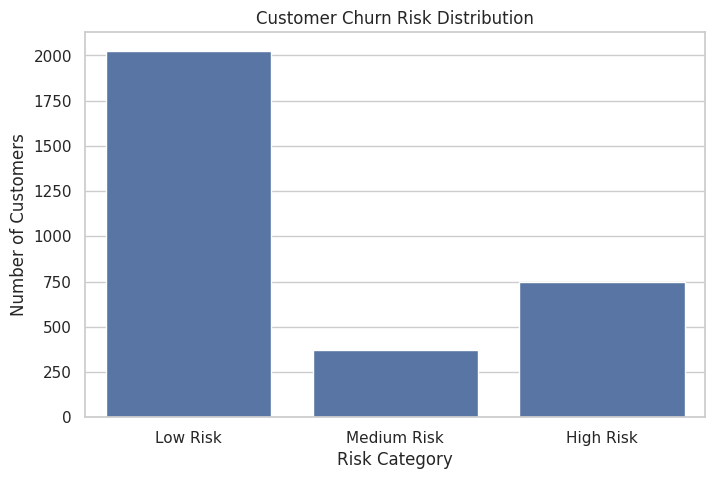

In [14]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)
coefficients = (
    model.named_steps["classifier"].coef_[0]
)
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)
print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15).round(4))
df["Churn_Probability"] = model.predict_proba(X)[:, 1]
df["Risk_Band"] = pd.cut(
    df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)
risk_summary = df.groupby(
    "Risk_Band",
    observed=False
).agg(
    Customers=("Churn", "size"),
    Actual_Churned=("Churn", "sum"),
    Actual_Churn_Rate=("Churn", "mean"),
    Average_Predicted_Risk=("Churn_Probability", "mean")
).reset_index()
risk_summary["Actual_Churn_Rate"] *= 100
risk_summary["Average_Predicted_Risk"] *= 100
print("\nCUSTOMER RISK SUMMARY")
display(risk_summary.round(2))
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Risk_Band",
    order=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)
plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.show()

In [15]:
CONTACT_RATE = 0.60
SAVE_RATE = 0.15
high_risk = df[
    df["Risk_Band"] == "High Risk"
]
high_risk_count = len(high_risk)
contacted = (
    high_risk_count * CONTACT_RATE
)
expected_saved = (
    contacted * SAVE_RATE
)
retention_report = pd.DataFrame({
    "Measure": [
        "High Risk Customers",
        "Assumed Contact Rate",
        "Expected Customers Contacted",
        "Assumed Save Rate",
        "Expected Customers Retained"
    ],
    "Value": [
        high_risk_count,
        CONTACT_RATE * 100,
        round(contacted, 2),
        SAVE_RATE * 100,
        round(expected_saved, 2)
    ]})
print("RETENTION IMPACT ESTIMATION")
display(retention_report)
print("""
BUSINESS RECOMMENDATIONS

1. Investigate customers with frequent call failures.

2. Improve customer complaint resolution.

3. Monitor customers with short subscription lengths.

4. Analyse low usage customers.

5. Review tariff plan performance.

6. Identify high-risk customers for retention campaigns.

7. Test retention strategies through controlled experiments.

IMPORTANT:
The contact rate and save rate are assumptions.
They are not actual measured campaign results.
""")

RETENTION IMPACT ESTIMATION


,Measure,Value
0,High Risk Customers,750.0
1,Assumed Contact Rate,60.0
2,Expected Customers Contacted,450.0
3,Assumed Save Rate,15.0
4,Expected Customers Retained,67.5



BUSINESS RECOMMENDATIONS

1. Investigate customers with frequent call failures.

2. Improve customer complaint resolution.

3. Monitor customers with short subscription lengths.

4. Analyse low usage customers.

5. Review tariff plan performance.

6. Identify high-risk customers for retention campaigns.

7. Test retention strategies through controlled experiments.

IMPORTANT:
The contact rate and save rate are assumptions.
They are not actual measured campaign results.



In [16]:
df.to_csv(
    "telecom_churn_analysis.csv",
    index=False
)
risk_report = df[[
    "Subscription_Length",
    "Call_Failure",
    "Complains",
    "Tariff_Plan",
    "Seconds_of_Use",
    "Frequency_of_use",
    "Frequency_of_SMS",
    "Churn",
    "Churn_Probability",
    "Risk_Band"
]]
risk_report.to_csv(
    "customer_risk_report.csv",
    index=False
)
metrics.to_csv(
    "model_performance.csv",
    index=False
)


# Save feature importance
importance_df.to_csv(
    "feature_importance.csv",
    index=False
)
retention_report.to_csv(
    "retention_impact_report.csv",
    index=False
)
print("All CSV reports created successfully!")
from google.colab import files
files.download("telecom_churn_analysis.csv")
files.download("customer_risk_report.csv")
files.download("model_performance.csv")
files.download("feature_importance.csv")
files.download("retention_impact_report.csv")

All CSV reports created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>